# Module 2: Exact Match LLM Caching

## 1. How Exact Match Caching Works
---

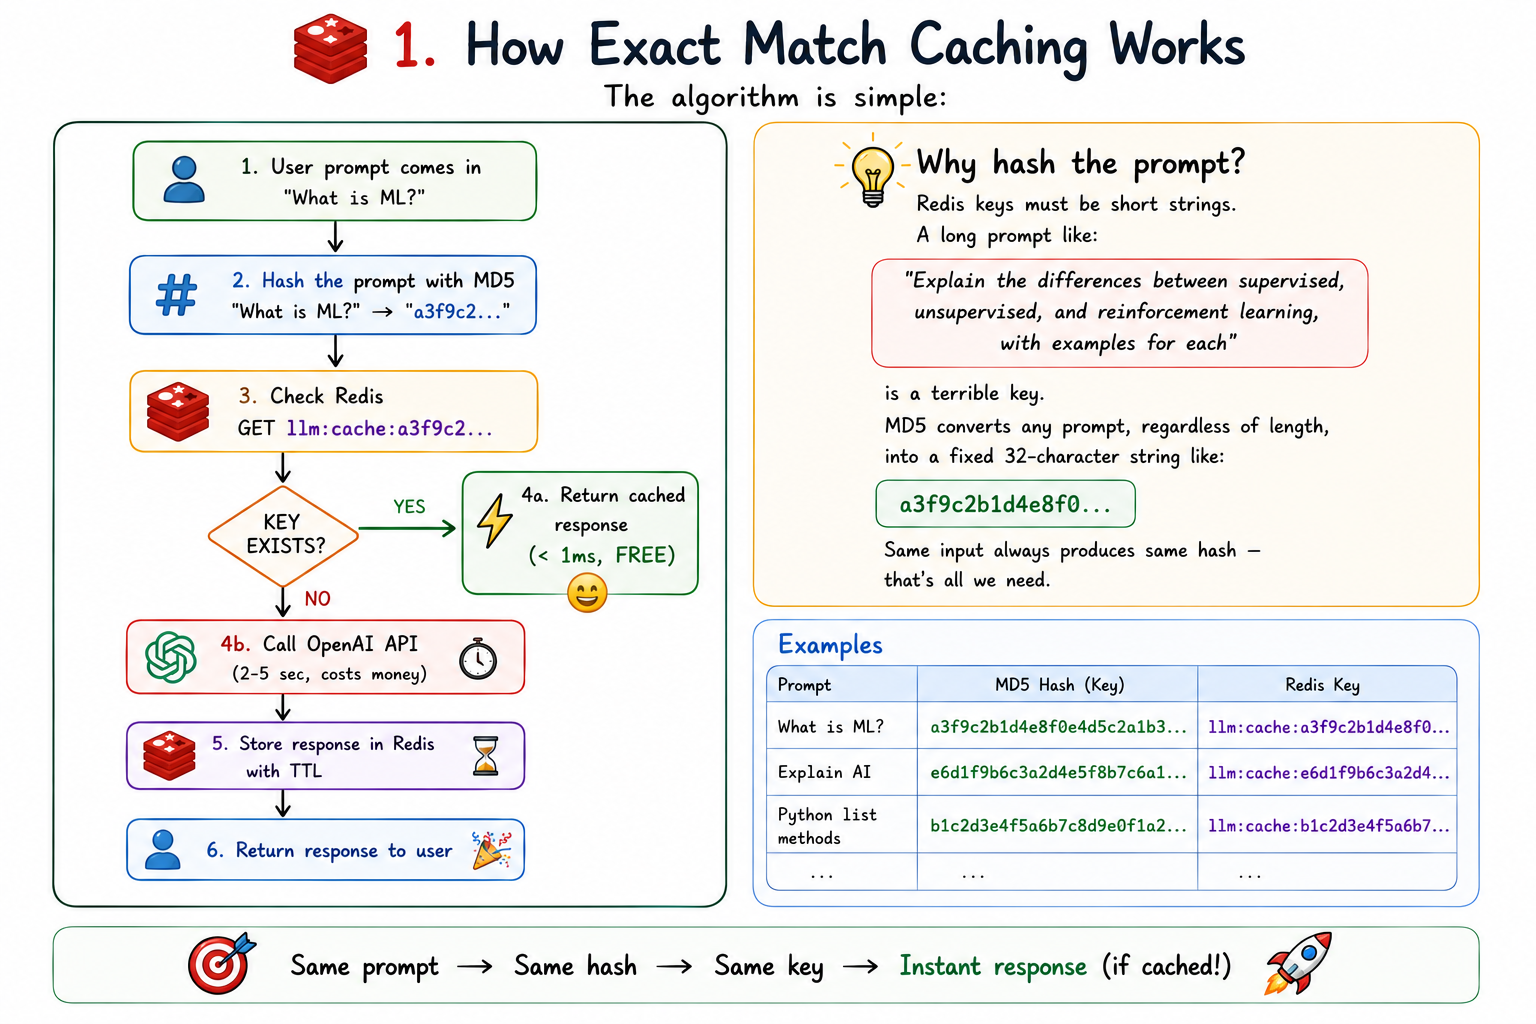

In [1]:
import redis
import openai
import hashlib
import json
import time
import os
from dotenv import load_dotenv

load_dotenv()

# Initialize Redis connection
r = redis.Redis(
    host=os.getenv('REDIS_HOST', 'localhost'),
    port=int(os.getenv('REDIS_PORT', 6379)),
    decode_responses=True
)

# Initialize OpenAI client
client = openai.OpenAI(api_key=os.getenv('OPENAI_API_KEY'))

# Quick health check
r.ping()
print("Redis connected!")
print(f"OpenAI API key loaded: {'Yes' if os.getenv('OPENAI_API_KEY') else 'NO - check your .env file!'}")

Redis connected!
OpenAI API key loaded: Yes


In [ ]:
# ─────────────────────────────────────────────────
# DEMO: What MD5 hashing looks like
# Same input ALWAYS produces the same hash
# ─────────────────────────────────────────────────

def make_cache_key(prompt: str) -> str:
    # Normalize: strip whitespace, lowercase — so "Hello" and "hello " both map to the same key
    normalized = prompt.strip().lower()
    hash_value = hashlib.md5(normalized.encode()).hexdigest()
    return f"llm:cache:{hash_value}"

# Show how keys are generated
test_prompts = [
    "What is machine learning?",
    "What is machine learning?",   # identical — same key
    "What is machine learning? ",  # trailing space — normalized away, still same key
    "What is deep learning?",      # different prompt — different key
]

print("Prompt -> Redis Cache Key")
print("-" * 70)
for p in test_prompts:
    key = make_cache_key(p)
    print(f"  '{p[:35]:35}' -> {key}")

print("\nNotice: The first three prompts produce the SAME key (exact match caching).")

Prompt -> Redis Cache Key
----------------------------------------------------------------------
  'What is machine learning?          ' -> llm:cache:0c9fdf1c9bd767b44887ab8491c4b9c0
  'What is machine learning?          ' -> llm:cache:0c9fdf1c9bd767b44887ab8491c4b9c0
  'What is machine learning?          ' -> llm:cache:0c9fdf1c9bd767b44887ab8491c4b9c0
  'What is deep learning?             ' -> llm:cache:28a3b39d74471f87bd1ec238a0efe079

Notice: The first three prompts produce the SAME key (exact match caching).


## 2. Building the Cache Functions

We need three helper functions:

- `get_from_cache(prompt)` — Check Redis for a stored response
- `save_to_cache(prompt, response)` — Store a new response in Redis  
- `ask_with_cache(prompt)` — The main function: check cache, then call API if needed

In [ ]:
# Cost per token for gpt-4o-mini (as of 2024)
# Input:  $0.15 per 1M tokens = $0.00000015 per token
# Output: $0.60 per 1M tokens = $0.00000060 per token
COST_PER_INPUT_TOKEN  = 0.00000015
COST_PER_OUTPUT_TOKEN = 0.00000060

def get_from_cache(prompt: str):
    """Returns cached data dict if found, else None."""
    key = make_cache_key(prompt)
    raw = r.get(key)
    if raw:
        return json.loads(raw)
    return None


def save_to_cache(prompt: str, response: str, token_info: dict, ttl_seconds: int = 3600):
    """Store an LLM response in Redis with a TTL."""
    key = make_cache_key(prompt)
    data = {
        "prompt": prompt,
        "response": response,
        "model": token_info.get("model", "unknown"),
        "input_tokens": token_info.get("input_tokens", 0),
        "output_tokens": token_info.get("output_tokens", 0),
        "cached_at": time.time()
    }
    r.set(key, json.dumps(data), ex=ttl_seconds)


def ask_with_cache(prompt: str, ttl: int = 3600) -> dict:
    """Ask the LLM with Redis caching. Returns result with metadata."""
    start = time.time()

    # Step 1: Check the cache
    cached = get_from_cache(prompt)
    if cached:
        elapsed_ms = (time.time() - start) * 1000
        return {
            "response": cached["response"],
            "source": "CACHE HIT",
            "time_ms": round(elapsed_ms, 2),
            "cost_usd": 0.0,
            "input_tokens": 0,
            "output_tokens": 0,
        }

    # Step 2: Cache miss — call the OpenAI API
    api_response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt}],
        max_tokens=300
    )

    elapsed_ms = (time.time() - start) * 1000
    response_text = api_response.choices[0].message.content
    input_tokens  = api_response.usage.prompt_tokens
    output_tokens = api_response.usage.completion_tokens
    cost = (input_tokens * COST_PER_INPUT_TOKEN) + (output_tokens * COST_PER_OUTPUT_TOKEN)

    # Step 3: Save to cache
    save_to_cache(prompt, response_text, {
        "model": "gpt-4o-mini",
        "input_tokens": input_tokens,
        "output_tokens": output_tokens
    }, ttl_seconds=ttl)

    return {
        "response": response_text,
        "source": "API CALL",
        "time_ms": round(elapsed_ms, 2),
        "cost_usd": round(cost, 8),
        "input_tokens": input_tokens,
        "output_tokens": output_tokens,
    }

print("Cache functions defined!")

Cache functions defined!


## 3. Live Demo — Cache Miss vs Cache Hit

We'll ask the same question twice. Watch what happens:
- **First call**: goes to OpenAI (slow, costs money)
- **Second call**: served from Redis (instant, free)

In [18]:
prompt = "What is the difference between supervised and unsupervised machine learning?"

print("FIRST CALL (expected: API CALL)")
print("-" * 50)
result1 = ask_with_cache(prompt)
print(f"Source   : {result1['source']}")
print(f"Time     : {result1['time_ms']} ms")
print(f"Cost     : ${result1['cost_usd']}")
print(f"Tokens   : {result1['input_tokens']} in / {result1['output_tokens']} out")
print(f"Response : {result1['response'][:150]}...")

FIRST CALL (expected: API CALL)
--------------------------------------------------
Source   : API CALL
Time     : 5206.47 ms
Cost     : $0.000183
Tokens   : 20 in / 300 out
Response : Supervised and unsupervised machine learning are two primary types of learning paradigms in the field of machine learning, and they differ mainly in t...


In [19]:
print("SECOND CALL — same prompt (expected: CACHE HIT)")
print("-" * 50)
result2 = ask_with_cache(prompt)
print(f"Source   : {result2['source']}")
print(f"Time     : {result2['time_ms']} ms")
print(f"Cost     : ${result2['cost_usd']}")
print(f"Response : {result2['response'][:150]}...")

print()
if result1["time_ms"] > 0 and result2["time_ms"] > 0:
    speedup = result1["time_ms"] / result2["time_ms"]
    print(f"Cache was {speedup:.0f}x faster than the API call!")

SECOND CALL — same prompt (expected: CACHE HIT)
--------------------------------------------------
Source   : CACHE HIT
Time     : 1.01 ms
Cost     : $0.0
Response : Supervised and unsupervised machine learning are two primary types of learning paradigms in the field of machine learning, and they differ mainly in t...

Cache was 5155x faster than the API call!


In [20]:
# ─────────────────────────────────────────────
# DEMO: Normalization — slightly different
# phrasing of the SAME question also hits cache
# because we strip and lowercase before hashing
# ─────────────────────────────────────────────

print("Testing normalization (trim + lowercase):")
print("-" * 50)

# These should all hit the cache from the call above
# because they normalize to the same string
variants = [
    "What is the difference between supervised and unsupervised machine learning?",
    "  What is the difference between supervised and unsupervised machine learning?  ",
    "WHAT IS THE DIFFERENCE BETWEEN SUPERVISED AND UNSUPERVISED MACHINE LEARNING?",
]

for v in variants:
    result = ask_with_cache(v)
    short_prompt = v.strip()[:55] + "..."
    print(f"  '{short_prompt}' -> {result['source']} ({result['time_ms']} ms)")

Testing normalization (trim + lowercase):
--------------------------------------------------
  'What is the difference between supervised and unsupervi...' -> CACHE HIT (1.0 ms)
  'What is the difference between supervised and unsupervi...' -> CACHE HIT (0.99 ms)
  'WHAT IS THE DIFFERENCE BETWEEN SUPERVISED AND UNSUPERVI...' -> CACHE HIT (0.5 ms)


## 4. TTL — Making Cache Entries Expire

Why set a TTL on cached LLM responses?

- **Freshness** — LLM models get updated; an old cached answer might be outdated
- **Memory management** — Without TTL, Redis fills up with stale data forever
- **Cost control** — Forcing occasional re-fetches ensures accuracy at the cost of a few extra API calls

**Typical TTL values for LLM caching:**

| Content Type | Suggested TTL |
|-------------|---------------|
| General knowledge questions | 24 hours - 7 days |
| News / current events | 1-6 hours |
| Product information | 12-24 hours |
| Code generation | 7 days |
| Conversations / memory | 1-4 hours |
| Embeddings | 30 days or permanent |

In [21]:
# Show TTL on a cached key
sample_prompt = "What is the difference between supervised and unsupervised machine learning?"
cache_key = make_cache_key(sample_prompt)

ttl_remaining = r.ttl(cache_key)
print(f"Cache key: {cache_key}")
print(f"TTL remaining: {ttl_remaining} seconds ({ttl_remaining / 60:.1f} minutes)")

# You can also update the TTL on an existing key
r.expire(cache_key, 7200)  # extend to 2 hours
print(f"After extending: {r.ttl(cache_key)} seconds ({r.ttl(cache_key) / 3600:.1f} hours)")

Cache key: llm:cache:5c4de453f7d244630799038b89efdb8f
TTL remaining: 3295 seconds (54.9 minutes)
After extending: 7200 seconds (2.0 hours)


## 5. Batch Demo — Multiple Questions

Let's ask several questions and see the caching in action across a realistic workload.

In [22]:
questions = [
    "What is a neural network?",
    "What is gradient descent?",
    "What is overfitting in machine learning?",
    "What is a neural network?",          # repeated!
    "What is gradient descent?",           # repeated!
    "What is transfer learning?",
    "What is overfitting in machine learning?",  # repeated!
    "What is a neural network?",          # repeated again!
]

total_cost   = 0.0
api_calls    = 0
cache_hits   = 0
total_time_ms = 0

print(f"{'#':>2}  {'Source':12}  {'Time(ms)':>10}  {'Cost':>10}  Question")
print("-" * 85)

for i, q in enumerate(questions, 1):
    result = ask_with_cache(q)
    total_cost    += result["cost_usd"]
    total_time_ms += result["time_ms"]
    
    if result["source"] == "CACHE HIT":
        cache_hits += 1
    else:
        api_calls += 1

    print(f"{i:>2}  {result['source']:12}  {result['time_ms']:>10.1f}  ${result['cost_usd']:>9.6f}  {q[:50]}")

print("-" * 85)
print(f"\nResults:")
print(f"  API calls    : {api_calls}   (paid)")
print(f"  Cache hits   : {cache_hits}   (free)")
print(f"  Cache hit rate: {cache_hits / len(questions) * 100:.0f}%")
print(f"  Total cost   : ${total_cost:.6f}")
print(f"  Total time   : {total_time_ms:.0f} ms")
print(f"\nWithout cache, all {len(questions)} calls would cost roughly ${total_cost / api_calls * len(questions):.6f}")
print(f"Cache saved approximately ${total_cost / api_calls * cache_hits:.6f} on this batch")

 #  Source          Time(ms)        Cost  Question
-------------------------------------------------------------------------------------
 1  API CALL          5628.8  $ 0.000182  What is a neural network?
 2  API CALL          4966.6  $ 0.000182  What is gradient descent?
 3  API CALL          4975.9  $ 0.000182  What is overfitting in machine learning?
 4  CACHE HIT            2.1  $ 0.000000  What is a neural network?
 5  CACHE HIT            1.0  $ 0.000000  What is gradient descent?
 6  API CALL          4453.9  $ 0.000148  What is transfer learning?
 7  CACHE HIT            1.1  $ 0.000000  What is overfitting in machine learning?
 8  CACHE HIT            0.0  $ 0.000000  What is a neural network?
-------------------------------------------------------------------------------------

Results:
  API calls    : 4   (paid)
  Cache hits   : 4   (free)
  Cache hit rate: 50%
  Total cost   : $0.000694
  Total time   : 20029 ms

Without cache, all 8 calls would cost roughly $0.001389
Cach

## 6. Inspecting What's Stored in Redis

In [23]:
# List all cached LLM responses currently in Redis
cache_keys = r.keys("llm:cache:*")
print(f"LLM responses cached in Redis: {len(cache_keys)}")
print()

for key in cache_keys:
    raw = r.get(key)
    data = json.loads(raw)
    ttl = r.ttl(key)
    prompt_preview = data['prompt'][:55] + "..." if len(data['prompt']) > 55 else data['prompt']
    print(f"Key    : {key}")
    print(f"Prompt : {prompt_preview}")
    print(f"Tokens : {data['input_tokens']} in / {data['output_tokens']} out")
    print(f"TTL    : {ttl} seconds remaining")
    print()

LLM responses cached in Redis: 5

Key    : llm:cache:84928bffbf2f35f61c26776a929dbae4
Prompt : What is overfitting in machine learning?
Tokens : 16 in / 300 out
TTL    : 3564 seconds remaining

Key    : llm:cache:5c4de453f7d244630799038b89efdb8f
Prompt : What is the difference between supervised and unsupervi...
Tokens : 20 in / 300 out
TTL    : 7088 seconds remaining

Key    : llm:cache:0952c25d39af6a32e7e8403229fe19f8
Prompt : What is transfer learning?
Tokens : 12 in / 244 out
TTL    : 3568 seconds remaining

Key    : llm:cache:8577ea75b5d245785e16c2bfc67e963b
Prompt : What is a neural network?
Tokens : 13 in / 300 out
TTL    : 3554 seconds remaining

Key    : llm:cache:48352deb7c41462a31d8e10f9fb88e86
Prompt : What is gradient descent?
Tokens : 12 in / 300 out
TTL    : 3559 seconds remaining



## 7. Cache Invalidation

Sometimes you need to **clear the cache** — for example, after updating your system prompt or when you want fresh responses.

Redis makes this easy:

In [24]:
def clear_llm_cache():
    """Delete all cached LLM responses."""
    keys = r.keys("llm:cache:*")
    if keys:
        r.delete(*keys)
    print(f"Cleared {len(keys)} cached responses from Redis")

def invalidate_prompt(prompt: str):
    """Invalidate the cache for one specific prompt."""
    key = make_cache_key(prompt)
    deleted = r.delete(key)
    if deleted:
        print(f"Removed cached response for: '{prompt[:60]}'")
    else:
        print(f"No cache entry found for: '{prompt[:60]}'")


In [25]:
# Show current cache size
print(f"Cache size before: {len(r.keys('llm:cache:*'))} entries")

Cache size before: 5 entries


In [26]:
# Invalidate just one prompt
invalidate_prompt("What is a neural network?")
print(f"Cache size after invalidating one: {len(r.keys('llm:cache:*'))} entries")


Removed cached response for: 'What is a neural network?'
Cache size after invalidating one: 4 entries


In [27]:
# Now verify it's a cache miss again
result = ask_with_cache("What is a neural network?")
print(f"\nAfter invalidation, next call source: {result['source']}")


After invalidation, next call source: API CALL


In [28]:
# Clean up all our demo cache entries
clear_llm_cache()
print(f"Final cache size: {len(r.keys('llm:cache:*'))} entries")

Cleared 5 cached responses from Redis
Final cache size: 0 entries
